## Download Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install gdown

!mkdir "/content/DataStorage"
!mkdir "/content/DataStorage/EEG_Classification"



In [3]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf/view?usp=sharing" \
  -O "/content/DataStorage/EEG_Classification/sub-03__63_channels.zip"

Downloading...
From (original): https://drive.google.com/uc?id=1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf
From (redirected): https://drive.google.com/uc?id=1vupFWT0OZHk_TLWeC_D5U1f3cKsqp5Xf&confirm=t&uuid=975a26a5-34a2-4114-b02b-85b798ff04e6
To: /content/DataStorage/EEG_Classification/sub-03__63_channels.zip
100% 4.03G/4.03G [01:04<00:00, 62.3MB/s]


In [4]:
!unzip -o "/content/DataStorage/EEG_Classification/sub-03__63_channels.zip" -d "/content/DataStorage/EEG_Classification/"

Archive:  /content/DataStorage/EEG_Classification/sub-03__63_channels.zip
   creating: /content/DataStorage/EEG_Classification/sub-03__63_channels/
  inflating: /content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_test.npy  
  inflating: /content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_training.npy  


In [5]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1ZM7FLolMjDGzz_gXE92jQZjDhc2pdP0W/view?usp=drive_link" \
  -O "/content/DataStorage/EEG_Classification/clip_embeddings_train.npy"

Downloading...
From: https://drive.google.com/uc?id=1ZM7FLolMjDGzz_gXE92jQZjDhc2pdP0W
To: /content/DataStorage/EEG_Classification/clip_embeddings_train.npy
100% 33.9M/33.9M [00:00<00:00, 54.6MB/s]


In [6]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/1cRuncV-FRI4JQHKD-rMg-CtZaZgT2TjO/view?usp=sharing" \
  -O "/content/DataStorage/EEG_Classification/clip_embeddings_test.npy"

Downloading...
From: https://drive.google.com/uc?id=1cRuncV-FRI4JQHKD-rMg-CtZaZgT2TjO
To: /content/DataStorage/EEG_Classification/clip_embeddings_test.npy
100% 410k/410k [00:00<00:00, 667kB/s]


In [7]:
!gdown --fuzzy \
  "https://drive.google.com/file/d/12UH2WjWaOuW4zejYnATrGmO0_9jl92w2/view?usp=drive_link" \
  -O "/content/DataStorage/EEG_Classification/eeg_image_mapping.csv"

Downloading...
From: https://drive.google.com/uc?id=12UH2WjWaOuW4zejYnATrGmO0_9jl92w2
To: /content/DataStorage/EEG_Classification/eeg_image_mapping.csv
100% 2.24M/2.24M [00:00<00:00, 16.1MB/s]


## Import library

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
random_state = 59
np.random.seed(random_state)
torch.manual_seed(random_state)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_state)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


## Processing data

In [9]:
data_train_path = "/content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_training.npy"
data_test_path = "/content/DataStorage/EEG_Classification/sub-03__63_channels/preprocessed_eeg_test.npy"


data_EEG_train = np.load(data_train_path, allow_pickle=True)
data_EEG_test = np.load(data_test_path, allow_pickle=True)



In [10]:
data_train_EEG_arr = data_EEG_train.item()['preprocessed_eeg_data']     # (16540, 4, 64, 100)
data_test_EEG_arr = data_EEG_test.item()["preprocessed_eeg_data"]       # (200, 80, 64, 100)

data_train_EEG_tensor = torch.from_numpy(data_train_EEG_arr).to(torch.float32)  # Size([16540, 4, 64, 100])
data_test_EEG_tensor = torch.from_numpy(data_test_EEG_arr).to(torch.float32)    # Size([200, 80, 64, 100])

# Get 63 channels

data_train_EEG_63_tensor = data_train_EEG_tensor[:,:,:63,:]   # 16540, 4, 63, 100
data_test_EEG_63_tensor = data_test_EEG_tensor[:,:,:63,:]     # 200, 80, 63, 100


In [11]:
# Data 63 channel EEG average session

data_train_EEG_63_tensor_avg = torch.mean(data_train_EEG_63_tensor, dim=1)    # 16540, 63, 100
data_test_EEG_63_tensor_avg = torch.mean(data_test_EEG_63_tensor, dim=1)      # 200, 63, 100

In [12]:
# Data CLIP embedding

data_CLIP_train_path = "/content/DataStorage/EEG_Classification/clip_embeddings_train.npy"
data_CLIP_test_path = "/content/DataStorage/EEG_Classification/clip_embeddings_test.npy"

data_CLIP_train = np.load(data_CLIP_train_path, allow_pickle=True)
data_CLIP_test = np.load(data_CLIP_test_path, allow_pickle=True)


data_CLIP_train_tensor = torch.from_numpy(data_CLIP_train)  # Size([16540, 512])
data_CLIP_test_tensor = torch.from_numpy(data_CLIP_test)    # Size([200, 512])


In [13]:
print(data_train_EEG_63_tensor.shape)
print(data_test_EEG_63_tensor.shape)

print(data_train_EEG_63_tensor_avg.shape)
print(data_test_EEG_63_tensor_avg.shape)

print(data_CLIP_train_tensor.shape)
print(data_CLIP_test_tensor.shape)

torch.Size([16540, 4, 63, 100])
torch.Size([200, 80, 63, 100])
torch.Size([16540, 63, 100])
torch.Size([200, 63, 100])
torch.Size([16540, 512])
torch.Size([200, 512])


In [14]:
# Get label for test data

import pandas as pd

# Converting the sharing link into a direct download link
file_id = "1NaE-lKVGFBFR7v5slUflu7tVpKAXlecL"
test_label_path = f"https://docs.google.com/uc?export=download&id={file_id}"

test_label = pd.read_csv(test_label_path)
label_test = test_label["concept"].tolist()

print(len(label_test))  # Expected: 200
print(label_test[:5])


200
['aircraft_carrier', 'antelope', 'backscratcher', 'balance_beam', 'banana']


## For NON-AVG experiment: Split data and Normalize data

In [15]:
# Get conceptID for training and valid

import pandas as pd
import numpy as np

csv_path = "/content/DataStorage/EEG_Classification/eeg_image_mapping.csv"

df = pd.read_csv(csv_path)

# Create integer concept IDs
df["concept_id"], unique_concepts = pd.factorize(df["concept"])

concept_ids = df["concept_id"].to_numpy()

print("Number of images:", len(df))
print("Number of concepts:", len(unique_concepts))
#print(df[["eeg_idx", "concept", "concept_id"]].head(15))

Number of images: 16540
Number of concepts: 1654


In [16]:
split_idx = 13230

val_idx = np.arange(split_idx, len(data_train_EEG_63_tensor_avg))

train_idx = np.arange(0, split_idx)

concept_ids_val = torch.tensor(
    df.iloc[val_idx]["concept_id"].to_numpy(),
    dtype=torch.long
)

concept_ids_train = torch.tensor(
    df.iloc[train_idx]["concept_id"].to_numpy(),
    dtype=torch.long
)

In [17]:


# Train: [13230, 4, 63, 100]
X_train_4session = data_train_EEG_63_tensor[train_idx]
Y_train_4session = data_CLIP_train_tensor[:split_idx]

# Expand sessions
X_train_4 = X_train_4session.reshape(-1, 63, 100)    # 52920, 63, 100
Y_train_4 = Y_train_4session.repeat_interleave(4, dim=0)   # Repeat CLIP embeddings and concept IDs # shape: 52920, 512
concept_ids_train_4 = concept_ids_train.repeat_interleave(4, dim=0)   # 52920

X_val_4 = data_train_EEG_63_tensor[val_idx]         # [3310, 4, 63, 100]
Y_val_4 = data_CLIP_train_tensor[split_idx:]        # Size([3310, 512])

X_test_80 = data_test_EEG_63_tensor


In [18]:
print(X_train_4.shape)

torch.Size([52920, 63, 100])


In [19]:
# Normalize data

mean_4 = X_train_4.mean(axis=(0, 2), keepdims=True)
std_4  = X_train_4.std(axis=(0, 2), keepdims=True)

X_train_norm_4 = (X_train_4 - mean_4) / (std_4 + 1e-8)  # 52920, 63, 100
X_val_norm_4   = (X_val_4   - mean_4) / (std_4 + 1e-8)  # 3310, 4, 63, 100
X_test_norm_80 = (X_test_80 - mean_4) / (std_4 + 1e-8)  # 200, 80, 63, 100


In [20]:
# Flatten EEG data test.
n_concepts, n_repetitions, n_channels, n_times = (
    X_test_norm_80.shape
)

X_test_norm_80_flat = X_test_norm_80.reshape(
    n_concepts * n_repetitions,
    n_channels,
    n_times
)   # 16000, 63, 100


In [21]:
import torch

concept_indices = torch.arange(n_concepts).repeat_interleave(n_repetitions)
repetition_indices = torch.arange(n_repetitions).repeat(n_concepts)

print(concept_indices.shape)    # (16000,)
print(repetition_indices.shape)  # (16000,)

torch.Size([16000])
torch.Size([16000])


## For NON-AVG experiment: Data Loader

In [22]:
import torch
from torch.utils.data import Sampler
from collections import defaultdict

class EEGDataset(Dataset):
    def __init__(self, X, y, concept_ids):
        self.X = X
        self.y = y
        self.concept_ids = concept_ids

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[idx],
            self.y[idx],
            self.concept_ids[idx]
        )


class UniqueConceptBatchSampler(Sampler):
    def __init__(
        self,
        concept_ids,
        batch_size=32,
        drop_last=True
    ):
        self.batch_size = batch_size
        self.drop_last = drop_last

        self.concept_to_indices = defaultdict(list)

        for idx, concept in enumerate(concept_ids.tolist()):
            self.concept_to_indices[int(concept)].append(idx)

        self.concepts = list(self.concept_to_indices.keys())

    def __iter__(self):
        # Shuffle concepts
        concept_order = torch.randperm(len(self.concepts)).tolist()

        selected_indices = []

        for i in concept_order:
            concept = self.concepts[i]
            candidates = self.concept_to_indices[concept]

            # Randomly select one image/session sample
            random_pos = torch.randint(len(candidates), (1,)).item()
            selected_indices.append(candidates[random_pos])

        # Create batches
        for i in range(0, len(selected_indices), self.batch_size):
            batch = selected_indices[i:i + self.batch_size]

            if len(batch) == self.batch_size or not self.drop_last:
                yield batch

    def __len__(self):
        if self.drop_last:
            return len(self.concepts) // self.batch_size
        return (len(self.concepts) + self.batch_size - 1) // self.batch_size


In [23]:
BATCH_SIZE = 32

train_dataset = EEGDataset(
    X_train_norm_4,
    Y_train_4,
    concept_ids_train_4
)

train_sampler = UniqueConceptBatchSampler(
    concept_ids_train_4,
    batch_size=BATCH_SIZE
)

train_loader = DataLoader(
    train_dataset,
    batch_sampler=train_sampler
)



In [24]:
val_loaders = []

for session in range(4):

    X_val_session = X_val_norm_4[:, session, :, :]

    val_dataset = EEGDataset(
        X_val_session,
        Y_val_4,
        concept_ids_val
    )

    val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
    )

    val_loaders.append(val_loader)



In [25]:
val_loss_loaders = []

for session in range(4):

    X_val_session = X_val_norm_4[:, session, :, :]

    val_dataset = EEGDataset(
        X_val_session,
        Y_val_4,
        concept_ids_val
    )

    val_sampler = UniqueConceptBatchSampler(
        concept_ids_val,
        batch_size=32,
        drop_last=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_sampler=val_sampler
    )

    val_loss_loaders.append(val_loader)

In [26]:
Y_test = data_CLIP_test_tensor
Y_test_repeated = Y_test.repeat_interleave(80, dim=0)

test_dataset_eval = EEGDataset(
    X_test_norm_80_flat,
    Y_test_repeated,
    concept_indices
)

test_loader = DataLoader(
    test_dataset_eval,
    batch_size=256,
    shuffle=False
)

In [27]:
# Check shape

# ==========================================
# 1. Check Training shapes
# ==========================================

assert X_train_norm_4.ndim == 3
assert X_train_norm_4.shape[1:] == (63, 100)

assert Y_train_4.shape == (X_train_norm_4.shape[0], 512)

assert len(concept_ids_train_4) == len(X_train_norm_4)


# ==========================================
# 2. Check Validation shapes
# ==========================================

assert X_val_norm_4.shape == (3310, 4, 63, 100)
assert Y_val_4.shape == (3310, 512)
assert len(concept_ids_val) == len(X_val_norm_4)

assert len(val_loaders) == 4

for loader in val_loaders:
    eeg, clip, concepts = next(iter(loader))

    assert eeg.shape[1:] == (63, 100)
    assert clip.shape[1] == 512
    assert eeg.shape[0] == clip.shape[0] == concepts.shape[0]


# ==========================================
# 3. Check unique concepts in every batch
# ==========================================

for eeg, clip, concepts in train_loader:

    assert len(torch.unique(concepts)) == len(concepts)


# ==========================================
# 4. Check concept leakage
# ==========================================

train_concepts = set(concept_ids_train.tolist())
val_concepts = set(concept_ids_val.tolist())

assert len(train_concepts.intersection(val_concepts)) == 0


# ==========================================
# 5. Check all repetitions are represented
# ==========================================

assert X_train_norm_4.shape[0] == 13230 * 4


print("All checks passed!")

All checks passed!


In [28]:
# ==========================================
# 6. Check Test shapes
# ==========================================

# Original test EEG: 200 concepts, 80 repetitions
assert X_test_norm_80.ndim == 4
assert X_test_norm_80.shape == (200, 80, 63, 100)

# Test CLIP embeddings
assert Y_test.shape == (200, 512)

# Check CLIP embeddings are finite
assert torch.isfinite(Y_test).all()

# Check concept indices
assert len(concept_indices) == 200*80
assert len(torch.unique(concept_indices)) == 200


# ==========================================
# 7. Flatten test EEG data
# ==========================================

n_concepts, n_repetitions, n_channels, n_times = (
    X_test_norm_80.shape
)

X_test_norm_80_flat = X_test_norm_80.reshape(
    n_concepts * n_repetitions,
    n_channels,
    n_times
)

assert X_test_norm_80_flat.shape == (16000, 63, 100)


# ==========================================
# 8. Repeat CLIP embeddings and labels
# ==========================================

Y_test_repeated = Y_test.repeat_interleave(
    n_repetitions,
    dim=0
)

concept_indices_repeated = torch.as_tensor(
    concept_indices,
    dtype=torch.long
)

assert concept_indices_repeated.shape == (16000,)
assert Y_test_repeated.shape == (16000, 512)



# ==========================================
# 9. Check EEG-CLIP alignment
# ==========================================

for i in range(n_concepts):

    start = i * n_repetitions
    end = (i + 1) * n_repetitions

    # 80 EEG repetitions must correspond to 1 image
    assert torch.allclose(
        Y_test_repeated[start:end],
        Y_test[i].unsqueeze(0).expand(n_repetitions, -1)
    )

    # All repetitions must have the same concept ID

    for i in range(200):
        start = i * 80
        end = (i + 1) * 80

        assert torch.all(
            concept_indices_repeated[start:end] == i
        )


# ==========================================
# 10. Create test DataLoader
# ==========================================

test_dataset_eval = EEGDataset(
    X_test_norm_80_flat,
    Y_test_repeated,
    concept_indices_repeated
)

test_loader = DataLoader(
    test_dataset_eval,
    batch_size=256,
    shuffle=False
)


# ==========================================
# 11. Check test DataLoader
# ==========================================

assert len(test_dataset_eval) == 16000

assert len(test_loader) == 63  # ceil(16000 / 256)

for eeg, clip, concepts in test_loader:

    assert eeg.ndim == 3
    assert eeg.shape[1:] == (63, 100)

    assert clip.shape[1] == 512

    assert eeg.shape[0] == clip.shape[0] == concepts.shape[0]

    assert torch.isfinite(eeg).all()
    assert torch.isfinite(clip).all()

# Check all 80 repetitions are preserved
assert len(test_dataset_eval) == 200 * 80


## Loss function and Metric

In [ ]:

# contrastive_loss

import torch
import torch.nn.functional as F

def contrastive_loss(eeg_embeddings, image_embeddings, temperature=0.07):
    # L2 normalize embeddings
    eeg_embeddings = F.normalize(eeg_embeddings.float(), dim=1)
    image_embeddings = F.normalize(image_embeddings.float(), dim=1)

    # Similarity matrix: (batch_size, batch_size)
    logits = eeg_embeddings @ image_embeddings.T

    # Temperature scaling
    logits = logits / temperature

    # Positive pairs on the main diagonal
    batch_size = eeg_embeddings.shape[0]
    labels = torch.arange(batch_size, device=eeg_embeddings.device)

    # EEG -> Image
    loss_eeg_to_image = F.cross_entropy(logits, labels)

    # Image -> EEG
    loss_image_to_eeg = F.cross_entropy(logits.T, labels)

    # Symmetric InfoNCE
    loss = (loss_eeg_to_image + loss_image_to_eeg) / 2

    return loss
# Metric for training


import torch
import torch.nn.functional as F

def recall_at_k(model, loader, device, k=5):
    model.eval()

    all_preds = []
    all_targets = []

    with torch.no_grad():
        for data, target, _ in loader:
            data = data.to(device)

            output = model(data)

            all_preds.append(output.cpu())
            all_targets.append(target.cpu())

    # [N, 512]
    all_preds = torch.cat(all_preds, dim=0)
    all_targets = torch.cat(all_targets, dim=0)

    # normalize data for cosine similarity
    all_preds = F.normalize(all_preds, p=2, dim=1)
    all_targets = F.normalize(all_targets, p=2, dim=1)

    # [N_query, N_candidates]
    similarity = all_preds @ all_targets.T

    # Top-k candidate / query
    k = min(k, all_targets.size(0))
    topk_indices = similarity.topk(k, dim=1).indices

    correct_indices = torch.arange(all_preds.size(0)).unsqueeze(1)

    hits = (topk_indices == correct_indices).any(dim=1)

    recall = hits.float().mean().item()

    return recall

# Metric for validation

import torch
import torch.nn.functional as F
import numpy as np

@torch.no_grad()
def recall_at_k_test_matched(
    model,
    loader,
    device,
    ks=(1, 5, 10),
    n_trials=200,
    seed=42
):
    model.eval()

    all_preds = []
    all_targets = []
    all_concept_ids = []

    #Predict all validation data
    for data, target, concept_id in loader:

        data = data.to(device)

        output = model(data)

        all_preds.append(output.cpu())
        all_targets.append(target.cpu())

        all_concept_ids.append(concept_id.cpu())

    all_preds = torch.cat(all_preds, dim=0)
    all_targets = torch.cat(all_targets, dim=0)
    all_concept_ids = torch.cat(all_concept_ids, dim=0).numpy()

    
    all_preds = F.normalize(all_preds, p=2, dim=1)
    all_targets = F.normalize(all_targets, p=2, dim=1)


    unique_concepts = np.unique(all_concept_ids)
    n_concepts = len(unique_concepts)

    
    concept_indices = {
        concept: np.where(all_concept_ids == concept)[0]
        for concept in unique_concepts
    }

    rng = np.random.default_rng(seed)

    results = {k: [] for k in ks}

    
    for trial in range(n_trials):

        selected_indices = []

        for concept in unique_concepts:

            candidates = concept_indices[concept]

            selected_idx = rng.choice(candidates)

            selected_indices.append(selected_idx)

        selected_indices = np.array(selected_indices)

        # EEG queries
        query = all_preds[selected_indices]

        # CLIP gallery
        gallery = all_targets[selected_indices]

        similarity = query @ gallery.T

        correct_similarity = similarity.diag().unsqueeze(1)

        ranks = (similarity > correct_similarity).sum(dim=1)

        for k in ks:

            k_actual = min(k, n_concepts)

            recall = (ranks < k_actual).float().mean().item()

            results[k].append(recall)

    summary = {}

    for k in ks:

        values = np.array(results[k])

        summary[f"Recall@{k}"] = {
            "mean": values.mean(),
            "std": values.std(),
            "chance": min(k, n_concepts) / n_concepts
        }

    return summary
# Metric for AVG testing

import torch
import torch.nn.functional as F
import numpy as np

def calculate_recall_at_k(
    eeg_embeddings,
    image_embeddings,
    eeg_concept_ids,
    image_concept_ids,
    ks=(1, 5, 10)
):
    """
    EEG-to-image retrieval.

    eeg_embeddings:      (N, 512)
    image_embeddings:    (M, 512)
    eeg_concept_ids:     (N,)
    image_concept_ids:   (M,)
    """

    eeg_embeddings = F.normalize(
        eeg_embeddings, p=2, dim=1
    )

    image_embeddings = F.normalize(
        image_embeddings, p=2, dim=1
    )

    # Similarity matrix: (N, M)
    similarity = eeg_embeddings @ image_embeddings.T

    # Map each EEG concept to its corresponding image index
    image_id_to_index = {
        int(concept_id): idx
        for idx, concept_id in enumerate(image_concept_ids)
    }

    assert len(image_id_to_index) == len(image_concept_ids), \
        "Duplicate image concept IDs detected."

    gt_indices = torch.tensor(
        [
            image_id_to_index[int(concept_id)]
            for concept_id in eeg_concept_ids
        ],
        device=similarity.device
    )

    # Ground-truth rank using top-k ordering
    sorted_indices = torch.argsort(
        similarity,
        dim=1,
        descending=True
    )

    # Find rank of ground-truth image
    ranks = (
        sorted_indices == gt_indices.unsqueeze(1)
    ).nonzero(as_tuple=False)[:, 1] + 1

    # Calculate Recall@K
    results = {}

    n_candidates = image_embeddings.shape[0]

    for k in ks:
        k_actual = min(k, n_candidates)

        recall = (
            (ranks <= k_actual).float().mean().item()
        )

        results[f"Recall@{k}"] = recall

    return results


### Initialization weight
import torch
import torch.nn as nn

def init_weights_he(m):
    if isinstance(m, (nn.Conv1d, nn.Linear)):
        # He initialization for layer has ReLU activation
        nn.init.kaiming_normal_(
            m.weight,
            mode='fan_in',
            nonlinearity='relu'
        )

        if m.bias is not None:
            nn.init.zeros_(m.bias)

    elif isinstance(m, (nn.BatchNorm1d, nn.LayerNorm)):
        if m.weight is not None:
            nn.init.ones_(m.weight)

        if m.bias is not None:
            nn.init.zeros_(m.bias)

## Model: MLP

In [53]:
class MLP(nn.Module):
    # Setup MLP layer
    def __init__(self, input_dims, hidden1_dims, hidden2_dims, output_dims):
        super(MLP,self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(input_dims, hidden1_dims)
        self.layerNorm = nn.LayerNorm(hidden1_dims)
        #self.linear2 = nn.Linear(hidden1_dims, hidden2_dims)
        self.output = nn.Linear(hidden1_dims, output_dims)

    # input --> Flatten --> linear1 --> layerNorm --> ReLU --> dropout(0.4) --> output
    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = self.layerNorm(x)
        x = F.relu(x)
        #x = self.linear2(x)
        #x = F.relu(x)
        x = F.dropout(x, p=0.4)
        output = self.output(x)
        return output

In [54]:
input_dims = 63*100

hidden1_dims = 1024
hidden2_dims = 512
output_dims = 512

model = MLP(input_dims=input_dims, hidden1_dims=hidden1_dims, hidden2_dims=hidden2_dims,  output_dims=output_dims).to(device)

model.apply(init_weights_he)

criterion = contrastive_loss
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-3
)

## Model: Conv1D

In [ ]:
class ImprovedConv1d_v2(nn.Module):
    def __init__(self, input_channels, output_dims):
        super(ImprovedConv1d_v2, self).__init__()
        # input: [Batch, 64, 100]
        self.conv_block1 = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2) # -> [Batch, 128, 50]
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv1d(in_channels=128, out_channels=256, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2) # -> [Batch, 256, 25]
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv1d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8)
        )

        # Flatten: 512 * 8 = 4096
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 8, 1024),
            nn.LayerNorm(1024),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(1024, output_dims)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.fc(x)
        return x

In [36]:
model = ImprovedConv1d_v2(input_channels=63, output_dims=512).to(device)

model.apply(init_weights_he)

criterion = contrastive_loss

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-3, weight_decay=1e-4)


## For NON-AVG experiment: Training and validation

In [37]:
!mkdir "/content/DataStorage/EEG_Classification/checkpoints"
!mkdir "/content/DataStorage/EEG_Classification/checkpoints/Experiment_NON-AVG"

In [55]:

import copy
import os
import torch

# ==========================================
# EXPERIMENT B: TRAIN WITH 4 EEG REPETITIONS
# ==========================================

epochs = 100

# Save path
save_dir = "/content/DataStorage/EEG_Classification/checkpoints/Experiment_NON-AVG"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(
    save_dir,
    "best_model_MLP.pth"
)

# ==========================================
# 1. INITIALIZE METRICS
# ==========================================

train_losses = []
val_losses = []

train_recalls_at_5 = []

# Validation loss: 4 repetitions
val_losses_by_rep = {
    f"rep_{s+1}": [] for s in range(4)
}

# Validation retrieval
val_recalls_at_5 = {
    f"rep_{s+1}": [] for s in range(4)
}

val_recalls_at_5_std = {
    f"rep_{s+1}": [] for s in range(4)
}

# Best model tracking
best_val_recall = float("-inf")
best_val_loss = None
best_epoch = 0

# ==========================================
# 2. TRAINING LOOP
# ==========================================

for epoch in range(epochs):

    train_loss = 0.0

    # =====================================
    # A. TRAINING
    # =====================================

    model.train()

    for X_samples, y_samples, _ in train_loader:

        X_samples = X_samples.to(device)
        y_samples = y_samples.to(device)

        optimizer.zero_grad()

        outputs = model(X_samples)

        loss = criterion(outputs, y_samples)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # =====================================
    # B. TRAIN RECALL@5
    # =====================================

    train_r5 = recall_at_k(
        model,
        train_loader,
        device,
        k=5
    )

    train_recalls_at_5.append(train_r5)

    # =====================================
    # C. VALIDATION LOSS
    #    Evaluate 4 repetitions separately
    # =====================================

    model.eval()

    session_val_losses = {}

    with torch.no_grad():

        for session, val_loader in enumerate(val_loss_loaders):

            val_loss = 0.0

            for X_samples, y_samples, _ in val_loader:

                X_samples = X_samples.to(device)
                y_samples = y_samples.to(device)

                outputs = model(X_samples)

                loss = criterion(outputs, y_samples)

                val_loss += loss.item()

            val_loss /= len(val_loader)

            session_name = f"rep_{session+1}"

            session_val_losses[session_name] = val_loss

            val_losses_by_rep[session_name].append(val_loss)

    # Mean validation loss across 4 repetitions
    val_loss_mean = sum(
        session_val_losses.values()
    ) / 4

    val_losses.append(val_loss_mean)

    # =====================================
    # D. VALIDATION TEST-MATCHED RECALL@5
    # =====================================

    session_results = {}

    for session, val_loader in enumerate(val_loaders):

        with torch.no_grad():

            val_result = recall_at_k_test_matched(
                model=model,
                loader=val_loader,
                device=device,
                ks=(5,),
                n_trials=200,
                seed=42
            )

        val_r5 = val_result["Recall@5"]["mean"]
        val_r5_std = val_result["Recall@5"]["std"]

        session_name = f"rep_{session+1}"

        val_recalls_at_5[session_name].append(val_r5)
        val_recalls_at_5_std[session_name].append(val_r5_std)

        session_results[session_name] = (
            val_r5,
            val_r5_std
        )

    # =====================================
    # E. MEAN VALIDATION RECALL@5
    # =====================================

    val_recall_mean = sum(
        r5 for r5, std in session_results.values()
    ) / 4

    val_recall_std = (
        sum(
            std ** 2
            for r5, std in session_results.values()
        ) / 4
    ) ** 0.5

    # =====================================
    # F. SAVE BEST MODEL
    #    Criterion: Highest mean Validation Recall@5
    # =====================================

    is_best_model = val_recall_mean > best_val_recall

    if is_best_model:

        best_val_recall = val_recall_mean
        best_val_loss = val_loss_mean
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        checkpoint = {
            "epoch": best_epoch,

            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),

            "best_val_recall": best_val_recall,
            "best_val_loss": best_val_loss,

            "train_loss": train_loss,
            "train_recall_at_5": train_r5,

            "val_losses_by_rep": copy.deepcopy(
                session_val_losses
            ),

            "val_recalls_at_5": {
                name: values[0]
                for name, values in session_results.items()
            },

            "val_recalls_at_5_std": {
                name: values[1]
                for name, values in session_results.items()
            },

            "val_recall_mean": val_recall_mean,
            "val_recall_std_across_reps": val_recall_std
        }

        torch.save(checkpoint, best_model_path)

    # =====================================
    # G. PRINT RESULTS
    # =====================================

    print(f"\nEPOCH {epoch + 1}/{epochs}:")

    print(f"\tTraining Loss: {train_loss:.4f}")
    print(f"\tValidation Loss (mean): {val_loss_mean:.4f}")
    print(f"\tTrain Recall@5: {train_r5:.4f}")

    for session_name, (r5, std) in session_results.items():

        print(
            f"\t{session_name}: "
            f"Val Loss = {session_val_losses[session_name]:.4f} | "
            f"Recall@5 = {r5:.4f} +/- {std:.4f}"
        )

    print(
        f"\tMean Validation Recall@5: "
        f"{val_recall_mean:.4f}"
    )

    print(
        f"\tMean Validation Recall@5 Std: "
        f"{val_recall_std:.4f}"
    )

    if is_best_model:

        print("\t>>> BEST MODEL UPDATED!")

        print(
            f"\t>>> Best Recall@5: "
            f"{best_val_recall:.4f}"
        )

        print(
            f"\t>>> Best Validation Loss: "
            f"{best_val_loss:.4f}"
        )

        print(f"\t>>> Saved: {best_model_path}")

    else:

        print(
            f"\tBest Model: Epoch {best_epoch} | "
            f"Recall@5 = {best_val_recall:.4f}"
        )


# ==========================================
# 3. FINAL BEST MODEL INFORMATION
# ==========================================

print("\n" + "=" * 55)
print("EXPERIMENT B - TRAINING COMPLETED")
print("=" * 55)

print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Recall@5: {best_val_recall:.4f}")
print(f"Validation Loss at Best Epoch: {best_val_loss:.4f}")

print(f"Best Model Path: {best_model_path}")



EPOCH 1/100:
	Training Loss: 3.5286
	Validation Loss (mean): 3.4835
	Train Recall@5: 0.0137
	rep_1: Val Loss = 3.4570 | Recall@5 = 0.0197 +/- 0.0068
	rep_2: Val Loss = 3.4780 | Recall@5 = 0.0199 +/- 0.0073
	rep_3: Val Loss = 3.4899 | Recall@5 = 0.0201 +/- 0.0072
	rep_4: Val Loss = 3.5090 | Recall@5 = 0.0177 +/- 0.0072
	Mean Validation Recall@5: 0.0193
	Mean Validation Recall@5 Std: 0.0071
	>>> BEST MODEL UPDATED!
	>>> Best Recall@5: 0.0193
	>>> Best Validation Loss: 3.4835
	>>> Saved: /content/DataStorage/EEG_Classification/checkpoints/Experiment_NON-AVG/best_model_MLP.pth

EPOCH 2/100:
	Training Loss: 3.4086
	Validation Loss (mean): 3.4491
	Train Recall@5: 0.0168
	rep_1: Val Loss = 3.4510 | Recall@5 = 0.0227 +/- 0.0069
	rep_2: Val Loss = 3.4695 | Recall@5 = 0.0216 +/- 0.0076
	rep_3: Val Loss = 3.4286 | Recall@5 = 0.0220 +/- 0.0081
	rep_4: Val Loss = 3.4475 | Recall@5 = 0.0215 +/- 0.0075
	Mean Validation Recall@5: 0.0220
	Mean Validation Recall@5 Std: 0.0075
	>>> BEST MODEL UPDATED!
	

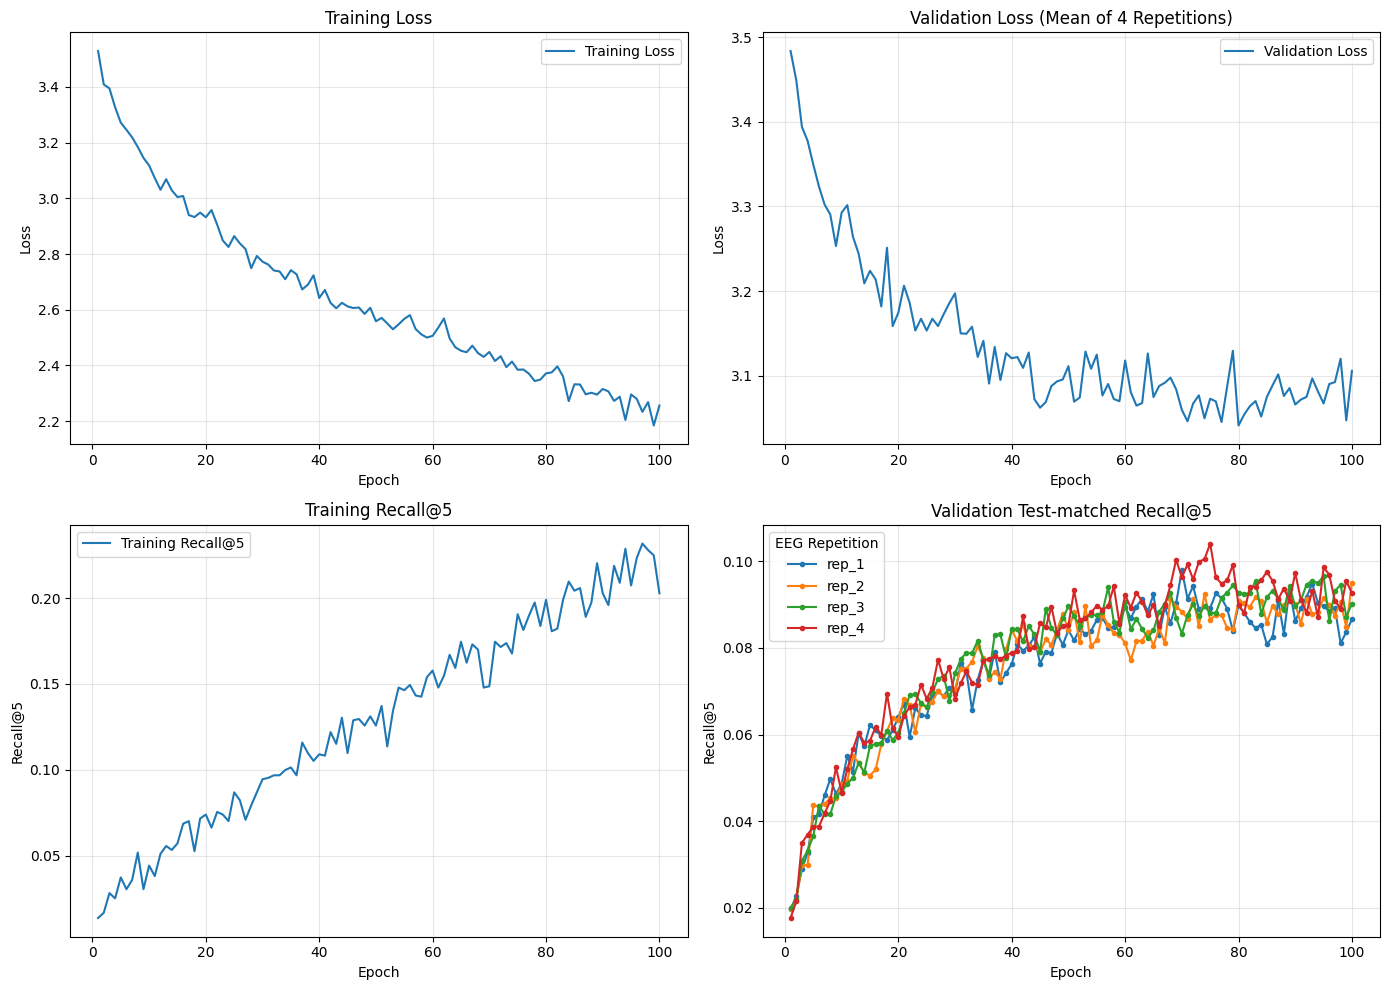

In [56]:
# Plot for 4 session

import matplotlib.pyplot as plt
import torch

# ==========================================
# 1. Convert metrics to CPU float
# ==========================================

def to_float_list(values):
    return [
        v.detach().cpu().item() if isinstance(v, torch.Tensor) else float(v)
        for v in values
    ]

train_loss_plot = to_float_list(train_losses)
val_loss_plot = to_float_list(val_losses)

train_recall_plot = to_float_list(train_recalls_at_5)

# Validation Recall@5 for 4 repetitions
val_recall_plot = {
    rep: to_float_list(values)
    for rep, values in val_recalls_at_5.items()
}

# ==========================================
# 2. Plot
# ==========================================

epochs_range = range(1, len(train_loss_plot) + 1)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# ------------------------------------------
# Training Loss
# ------------------------------------------

ax[0, 0].plot(
    epochs_range,
    train_loss_plot,
    label="Training Loss"
)

ax[0, 0].set(
    xlabel="Epoch",
    ylabel="Loss",
    title="Training Loss"
)

ax[0, 0].grid(True, alpha=0.3)
ax[0, 0].legend()


# ------------------------------------------
# Validation Loss
# ------------------------------------------

ax[0, 1].plot(
    epochs_range,
    val_loss_plot,
    label="Validation Loss"
)

ax[0, 1].set(
    xlabel="Epoch",
    ylabel="Loss",
    title="Validation Loss (Mean of 4 Repetitions)"
)

ax[0, 1].grid(True, alpha=0.3)
ax[0, 1].legend()


# ------------------------------------------
# Training Recall@5
# ------------------------------------------

ax[1, 0].plot(
    epochs_range,
    train_recall_plot,
    label="Training Recall@5"
)

ax[1, 0].set(
    xlabel="Epoch",
    ylabel="Recall@5",
    title="Training Recall@5"
)

ax[1, 0].grid(True, alpha=0.3)
ax[1, 0].legend()


# ------------------------------------------
# Validation Recall@5 (4 repetitions)
# ------------------------------------------

for rep, values in val_recall_plot.items():

    ax[1, 1].plot(
        epochs_range,
        values,
        marker="o",
        markersize=3,
        label=rep
    )

ax[1, 1].set(
    xlabel="Epoch",
    ylabel="Recall@5",
    title="Validation Test-matched Recall@5"
)

ax[1, 1].grid(True, alpha=0.3)
ax[1, 1].legend(title="EEG Repetition")


# ==========================================
# 3. Final layout
# ==========================================

plt.tight_layout()
plt.show()


## Testing

In [41]:
!pip -q install gdown

# !mkdir "/content/DataStorage/EEG_Classification/checkpoints"
!mkdir "/content/DataStorage/EEG_Classification/checkpoints/Experiment_AVG"
# !mkdir "/content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg"
!mkdir "/content/DataStorage/EEG_Classification/results"


In [42]:
# ==========================================
# DOWNLOAD MODEL CHECKPOINTS
# ==========================================

!pip -q install gdown

import os
import gdown

# Base directory
base_dir = "/content/DataStorage/EEG_Classification/checkpoints"

# Google Drive links and corresponding save paths
files = {
    "Exp_avg": {
        "best_model_MLP.pth":
            "https://drive.google.com/file/d/1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P/view?usp=drive_link",

        "best_model_Conv1D.pth":
            "https://drive.google.com/file/d/1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e/view?usp=drive_link"
    },

    "Exp_non_avg": {
        "best_model_MLP.pth":
            "https://drive.google.com/file/d/14MEhmLPzHQtZP449ahHWUPv0JXdj_ZaI/view?usp=drive_link",

        "best_model_Conv1D.pth":
            "https://drive.google.com/file/d/1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ/view?usp=drive_link"
    }
}

# Create folders and download files
for experiment, model_files in files.items():

    save_dir = os.path.join(base_dir, experiment)
    os.makedirs(save_dir, exist_ok=True)

    print(f"\nDownloading {experiment}...")

    for filename, url in model_files.items():

        output_path = os.path.join(save_dir, filename)

        print(f"Downloading {filename}...")

        result = gdown.download(
            url=url,
            output=output_path,
            quiet=False,
            fuzzy=True
        )

        if result is None:
            print(f"Download failed: {filename}")
        else:
            print(f"Saved to: {output_path}")

print("\nDownload process completed!")

Downloading...
From (original): https://drive.google.com/uc?id=1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P
From (redirected): https://drive.google.com/uc?id=1R0ed0pSv91ILe6mmSgcbdhN8yqe9IP4P&confirm=t&uuid=5e6d255c-0830-4b64-8efc-944717016526
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth
100%|██████████| 83.8M/83.8M [00:01<00:00, 52.3MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth


Downloading...
From (original): https://drive.google.com/uc?id=1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e
From (redirected): https://drive.google.com/uc?id=1zLdpnrHsKctKjQkC-G41Qtg9srPh2_0e&confirm=t&uuid=9a47454e-32d8-441a-91c1-21048cb374df
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth
100%|██████████| 63.9M/63.9M [00:01<00:00, 51.9MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth



Downloading...
From (original): https://drive.google.com/uc?id=14MEhmLPzHQtZP449ahHWUPv0JXdj_ZaI
From (redirected): https://drive.google.com/uc?id=14MEhmLPzHQtZP449ahHWUPv0JXdj_ZaI&confirm=t&uuid=40ac0ae3-774f-4e92-b3f7-8d1097c02d55
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_MLP.pth
100%|██████████| 83.7M/83.7M [00:01<00:00, 56.1MB/s]


Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_MLP.pth


Downloading...
From (original): https://drive.google.com/uc?id=1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ
From (redirected): https://drive.google.com/uc?id=1l4ZVm3LKLt6MlbG6SKkNiqhfMVNqwJSJ&confirm=t&uuid=b909975d-9b08-408d-b753-d0ecf51d46a0
To: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth
100%|██████████| 63.9M/63.9M [00:00<00:00, 65.9MB/s]

Saved to: /content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth

Download process completed!


In [57]:
import torch
import numpy as np
import pandas as pd
import os

# ==========================================
# MODEL CHECKPOINTS
# ==========================================

model_paths = {
    "Experiment_MLP_Avg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_MLP.pth",
    "Experiment_Conv1D_avg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_avg/best_model_Conv1D.pth",
    "Experiment_MLP_NonAvg": "/content/DataStorage/EEG_Classification/checkpoints/Experiment_NON-AVG/best_model_MLP.pth",
    "Experiment_Conv1d_NonAvg": "/content/DataStorage/EEG_Classification/checkpoints/Exp_non_avg/best_model_Conv1D.pth"
}

In [58]:
# ==========================================
# INITIALIZE 4 MODELS
# ==========================================

input_dims_mlp = 63 * 100

models = {
    "Experiment_MLP_Avg": MLP(
        input_dims=input_dims_mlp,
        hidden1_dims=1024,
        hidden2_dims=512,
        output_dims=512
    ),

    "Experiment_Conv1D_avg": ImprovedConv1d_v2(
        input_channels=63,
        output_dims=512
    ),

    "Experiment_MLP_NonAvg": MLP(
        input_dims=input_dims_mlp,
        hidden1_dims=1024,
        hidden2_dims=512,
        output_dims=512
    ),

    "Experiment_Conv1d_NonAvg": ImprovedConv1d_v2(
        input_channels=63,
        output_dims=512
    )
}

In [59]:
# ==========================================
# LOAD BEST CHECKPOINTS
# ==========================================

for model_name, model in models.items():

    checkpoint = torch.load(
        model_paths[model_name],
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(device)
    model.eval()

    print(
        f"{model_name}: "
        f"Loaded from epoch {checkpoint['epoch']}"
    )

Experiment_MLP_Avg: Loaded from epoch 3
Experiment_Conv1D_avg: Loaded from epoch 7
Experiment_MLP_NonAvg: Loaded from epoch 95
Experiment_Conv1d_NonAvg: Loaded from epoch 100


## For NON-AVG: Tesing

In [60]:
# ==========================================
# EVALUATE 4 MODELS ON THE SAME TEST SET
# ==========================================

results = {}

for model_name, model in models.items():

    print(f"\nEvaluating {model_name}...")

    model.eval()

    with torch.no_grad():

        test_result = recall_at_k_test_matched(
            model=model,
            loader=test_loader,
            device=device,
            ks=(1, 5, 10),
            n_trials=200,
            seed=42
        )

    results[model_name] = {
        "Recall@1": test_result["Recall@1"]["mean"],
        "Recall@5": test_result["Recall@5"]["mean"],
        "Recall@10": test_result["Recall@10"]["mean"],

        "Recall@1_std": test_result["Recall@1"]["std"],
        "Recall@5_std": test_result["Recall@5"]["std"],
        "Recall@10_std": test_result["Recall@10"]["std"]
    }

    print(
        f"Recall@1: "
        f"{results[model_name]['Recall@1']:.4f}"
    )

    print(
        f"Recall@5: "
        f"{results[model_name]['Recall@5']:.4f}"
    )

    print(
        f"Recall@10: "
        f"{results[model_name]['Recall@10']:.4f}"
    )


Evaluating Experiment_MLP_Avg...
Recall@1: 0.0284
Recall@5: 0.1120
Recall@10: 0.1909

Evaluating Experiment_Conv1D_avg...
Recall@1: 0.0306
Recall@5: 0.1247
Recall@10: 0.2052

Evaluating Experiment_MLP_NonAvg...
Recall@1: 0.0315
Recall@5: 0.1165
Recall@10: 0.2001

Evaluating Experiment_Conv1d_NonAvg...
Recall@1: 0.0384
Recall@5: 0.1563
Recall@10: 0.2593


In [ ]:
# ==========================================
# SUMMARY RESULTS
# ==========================================

results_df = pd.DataFrame(results).T

print("\nFINAL TEST RESULTS:")
display(results_df)

# Save results
results_df.to_csv(
    "/content/DataStorage/EEG_Classification/result/4_models_test_comparison.csv"
)


FINAL TEST RESULTS:


,Recall@1,Recall@5,Recall@10,Recall@1_std,Recall@5_std,Recall@10_std
Experiment_MLP_Avg,0.028325,0.111950,0.195725,0.011665,0.020511,0.026783
Experiment_Conv1D_avg,0.032650,0.126925,0.212700,0.011575,0.022686,0.025869
Experiment_MLP_NonAvg,0.032300,0.128625,0.217550,0.011201,0.020700,0.023580
Experiment_Conv1d_NonAvg,0.029550,0.137625,0.240175,0.010089,0.021616,0.024766


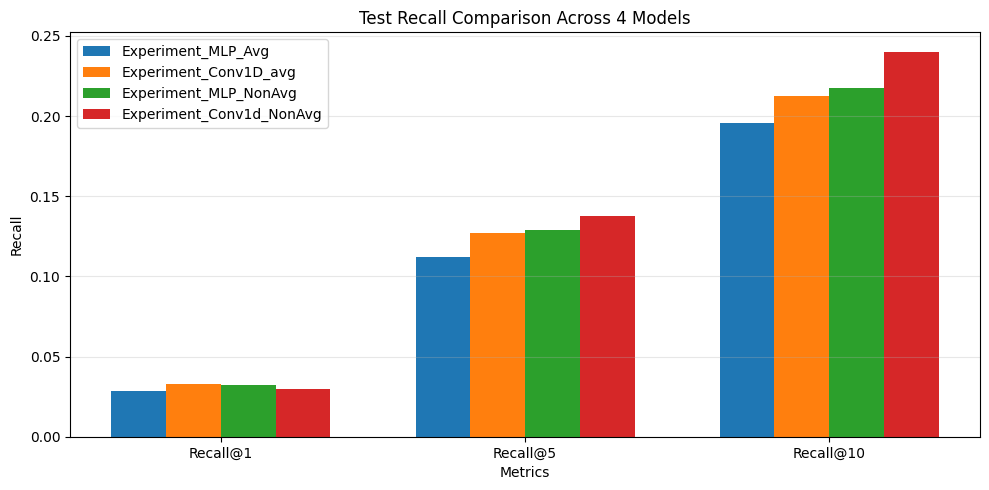

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# PLOT TEST RECALL COMPARISON
# ==========================================

metrics = ["Recall@1", "Recall@5", "Recall@10"]

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(metrics))
width = 0.18

for i, model_name in enumerate(results.keys()):

    values = [
        results[model_name][metric]
        for metric in metrics
    ]

    ax.bar(
        x + i * width,
        values,
        width,
        label=model_name
    )

ax.set_xlabel("Metrics")
ax.set_ylabel("Recall")
ax.set_title("Test Recall Comparison Across 4 Models")

ax.set_xticks(
    x + width * (len(results) - 1) / 2
)

ax.set_xticklabels(metrics)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()